# QuizNet – Multiplayer Quiz System
## Name: Kolimi Mahesh
## Roll No: 2025BCS0077
**Python course project**

In this project, I am building a small quiz system. A player connects to a Python server, answers multiple-choice questions, and gets a score at the end. MySQL stores the questions and scores. Sockets are used for communication, and threading lets the server handle more than one player. NetworkX draws the system architecture, and Matplotlib displays a graph of student quiz performance.



## 1. Install the required packages



In [1]:
%pip install mysql-connector-python pandas networkx matplotlib

Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 26.1.2 -> 26.2.1
[notice] To update, run: C:\Users\Chandrashekara\AppData\Local\Python\pythoncore-3.14-64\python.exe -m pip install --upgrade pip


## 2. Set up MySQL and the server settings

Run this cell and enter your MySQL password when asked. The password is hidden while typing. The server uses port `5055`. For the first test, the client and server will run on the same laptop.

In [2]:
# Standard library modules for networking, concurrency, JSON messages, and hidden password input.
# pandas is used to show result history as a table; mysql.connector connects Python to MySQL.

import socket
import threading
import json
import getpass
import pandas as pd
import mysql.connector
from mysql.connector import Error

MYSQL_HOST = "127.0.0.1"
MYSQL_USER = "root"
MYSQL_PASSWORD = getpass.getpass("Enter MySQL password (input is hidden): ")
DATABASE = "quiz_M_db"
SERVER_HOST = "0.0.0.0"
SERVER_PORT = 5055
print("Configuration loaded.")

Enter MySQL password (input is hidden):  ········


Configuration loaded.


## 3. Create the database and tables

This cell creates a database named `quiznet_db` and two tables: `questions` and `results`. Make sure MySQL is running and that the username and password in the previous part are correct. If you get an access-denied error, check your login details and permissions.

In [3]:
# Open a MySQL connection. The database name is omitted only when creating the database itself.

def get_db_connection(include_database=True):
    config = {"host": MYSQL_HOST, "user": MYSQL_USER, "password": MYSQL_PASSWORD}
    if include_database:
        config["database"] = DATABASE
    return mysql.connector.connect(**config)

def initialize_database():
    conn = get_db_connection(False)
    cur = conn.cursor()
    cur.execute(f"CREATE DATABASE IF NOT EXISTS {DATABASE}")
    cur.close()
    conn.close()
    conn = get_db_connection()
    cur = conn.cursor()
    cur.execute("""
        CREATE TABLE IF NOT EXISTS questions (
            question_id INT AUTO_INCREMENT PRIMARY KEY,
            question_text VARCHAR(500) NOT NULL,
            option_a VARCHAR(255) NOT NULL,
            option_b VARCHAR(255) NOT NULL,
            option_c VARCHAR(255) NOT NULL,
            option_d VARCHAR(255) NOT NULL,
            correct_option CHAR(1) NOT NULL,
            topic VARCHAR(100) DEFAULT 'General'
        )
    """)
    cur.execute("""
        CREATE TABLE IF NOT EXISTS results (
            result_id INT AUTO_INCREMENT PRIMARY KEY,
            player_name VARCHAR(100) NOT NULL,
            score INT NOT NULL,
            total_questions INT NOT NULL,
            percentage DECIMAL(5,2) NOT NULL,
            completed_at TIMESTAMP DEFAULT CURRENT_TIMESTAMP
        )
    """)
    conn.commit()
    cur.close()
    conn.close()
    print("Database and tables are ready.")

initialize_database()

Database and tables are ready.


## 4. Add some sample questions

This cell adds five sample questions if the table is empty. Running it again should not add the same sample questions again. You can add questions using the helper function in 5.

In [4]:
# Insert starter questions only if no questions exist, preventing duplicates on repeated runs.

def seed_sample_questions():
    sample = [
        ("Which keyword defines a function in Python?", "func", "def", "function", "define", "B", "Python"),
        ("Which data structure stores key-value pairs?", "List", "Tuple", "Dictionary", "Set", "C", "Python"),
        ("Which protocol is connection-oriented?", "UDP", "TCP", "IP", "DNS", "B", "Networking"),
        ("Which SQL command retrieves data?", "GET", "OPEN", "SELECT", "FETCHALL", "C", "MySQL"),
        ("Which Python module provides basic TCP sockets?", "socket", "http", "email", "pathlib", "A", "Networking"),
    ]
    conn = get_db_connection()
    cur = conn.cursor()
    cur.execute("SELECT COUNT(*) FROM questions")
    count = cur.fetchone()[0]
    if count == 0:
        cur.executemany("""
            INSERT INTO questions
            (question_text, option_a, option_b, option_c, option_d, correct_option, topic)
            VALUES (%s, %s, %s, %s, %s, %s, %s)
        """, sample)
        conn.commit()
        print(f"Inserted {len(sample)} sample questions.")
    else:
        print(f"Questions table already has {count} question(s); no duplicates inserted.")
    cur.close()
    conn.close()

seed_sample_questions()

Questions table already has 5 question(s); no duplicates inserted.


## 5. Add and view questions

`add_question(...)` saves a new question in MySQL. The correct option should be `A`, `B`, `C`, or `D`. `view_questions()` shows the questions already stored in the database.

In [5]:
# Admin helper: validate the correct option and store question fields using parameterized SQL.

def add_question(question, option_a, option_b, option_c, option_d, correct_option, topic="General"):
    correct_option = correct_option.strip().upper()
    if correct_option not in {"A", "B", "C", "D"}:
        raise ValueError("correct_option must be A, B, C, or D")
    conn = get_db_connection()
    cur = conn.cursor()
    cur.execute("""
        INSERT INTO questions
        (question_text, option_a, option_b, option_c, option_d, correct_option, topic)
        VALUES (%s, %s, %s, %s, %s, %s, %s)
    """, (question, option_a, option_b, option_c, option_d, correct_option, topic))
    conn.commit()
    cur.close()
    conn.close()
    print("Question added.")

def view_questions():
    conn = get_db_connection()
    cur = conn.cursor(dictionary=True)
    cur.execute("SELECT question_id, question_text, topic FROM questions ORDER BY question_id")
    rows = cur.fetchall()
    cur.close()
    conn.close()
    for row in rows:
        print(f'{row["question_id"]}. [{row["topic"]}] {row["question_text"]}')
    return rows

view_questions()

1. [Python] Which keyword defines a function in Python?
2. [Python] Which data structure stores key-value pairs?
3. [Networking] Which protocol is connection-oriented?
4. [MySQL] Which SQL command retrieves data?
5. [Networking] Which Python module provides basic TCP sockets?


[{'question_id': 1,
  'question_text': 'Which keyword defines a function in Python?',
  'topic': 'Python'},
 {'question_id': 2,
  'question_text': 'Which data structure stores key-value pairs?',
  'topic': 'Python'},
 {'question_id': 3,
  'question_text': 'Which protocol is connection-oriented?',
  'topic': 'Networking'},
 {'question_id': 4,
  'question_text': 'Which SQL command retrieves data?',
  'topic': 'MySQL'},
 {'question_id': 5,
  'question_text': 'Which Python module provides basic TCP sockets?',
  'topic': 'Networking'}]

## 6. Functions that use the database

These functions get questions from MySQL and save each player's score after the quiz. The score, number of questions, and percentage are stored so they can be shown later.

In [6]:
# Database helpers used by the server to retrieve questions and persist completed quiz attempts.

def load_questions():
    conn = get_db_connection()
    cur = conn.cursor(dictionary=True)
    cur.execute("""
        SELECT question_id, question_text, option_a, option_b, option_c, option_d, correct_option
        FROM questions ORDER BY question_id
    """)
    rows = cur.fetchall()
    cur.close()
    conn.close()
    return rows

def save_result(player_name, score, total):
    percentage = round(score * 100 / total, 2) if total else 0
    conn = get_db_connection()
    cur = conn.cursor()
    cur.execute("""
        INSERT INTO results (player_name, score, total_questions, percentage)
        VALUES (%s, %s, %s, %s)
    """, (player_name, score, total, percentage))
    conn.commit()
    cur.close()
    conn.close()
    return percentage

## 7. Set up the quiz server

This part defines how the server communicates with the clients. Messages are sent as JSON text. The server uses a separate thread for each connected player. The correct answers stay on the server instead of being sent to the client.

In [7]:
# Messages are JSON followed by a newline, so the receiver can read one complete message at a time.

def send_json(writer, data):
    writer.write((json.dumps(data) + "\n").encode("utf-8"))
    writer.flush()

def receive_json(reader):
    line = reader.readline()
    if not line:
        return None
    return json.loads(line.decode("utf-8"))

class QuizTCPServer:
    def __init__(self, host=SERVER_HOST, port=SERVER_PORT):
        self.host, self.port = host, port
        self.server_socket = None
        self.thread = None
        self.running = False

    def start(self):
        if self.running:
            print("Server is already running.")
            return
        self.server_socket = socket.socket(socket.AF_INET, socket.SOCK_STREAM)
        self.server_socket.setsockopt(socket.SOL_SOCKET, socket.SO_REUSEADDR, 1)
        self.server_socket.bind((self.host, self.port))
        self.server_socket.listen(10)
        self.server_socket.settimeout(1.0)
        self.running = True
        self.thread = threading.Thread(target=self._accept_clients, daemon=True)
        self.thread.start()
        print(f"Quiz server listening on {self.host}:{self.port}")

    def _accept_clients(self):
        while self.running:
            try:
                client, address = self.server_socket.accept()
                print("Client connected:", address)
                threading.Thread(target=self._handle_client, args=(client,), daemon=True).start()
            except socket.timeout:
                continue
            except OSError:
                break

    def _handle_client(self, client):
        try:
            with client:
                reader, writer = client.makefile("rb"), client.makefile("wb")
                request = receive_json(reader)
                if not request or request.get("type") != "join":
                    send_json(writer, {"type": "error", "message": "Invalid join request"})
                    return
                name = str(request.get("name", "Player")).strip()[:100] or "Player"
                questions = load_questions()
                if not questions:
                    send_json(writer, {"type": "error", "message": "No questions available"})
                    return
                send_json(writer, {"type": "start", "total": len(questions)})
                score = 0
                for i, q in enumerate(questions, start=1):
                    send_json(writer, {
                        "type": "question", "number": i, "total": len(questions),
                        "question": q["question_text"],
                        "options": {"A": q["option_a"], "B": q["option_b"],
                                    "C": q["option_c"], "D": q["option_d"]}
                    })
                    answer_message = receive_json(reader)
                    answer = (answer_message or {}).get("answer", "").strip().upper()
                    if answer == q["correct_option"]:
                        score += 1
                    send_json(writer, {"type": "feedback", "correct": answer == q["correct_option"]})
                percentage = save_result(name, score, len(questions))
                send_json(writer, {"type": "finished", "name": name, "score": score,
                                   "total": len(questions), "percentage": percentage})
                print(f"{name}: {score}/{len(questions)}")
        except Exception as exc:
            print("Client session error:", exc)

    def stop(self):
        self.running = False
        if self.server_socket:
            try:
                self.server_socket.close()
            except OSError:
                pass
        print("Server stop requested.")

quiz_server = QuizTCPServer()

## 8. Start the server

Run this cell once after the earlier sections work. You should see a message saying that the quiz server is listening on port `5055`. If the port is already being used, change `SERVER_PORT` in 2 and rerun the needed cells. Do not start the server more than once.

In [8]:
# Start the listening socket once; the server runs in a background thread so notebook execution continues.

quiz_server.start()

Quiz server listening on 0.0.0.0:5055


## 9. Set up the quiz client

In [9]:
# 9. Set up the quiz client

def play_quiz(player_name, answers=None, host="127.0.0.1", port=SERVER_PORT):
    with socket.create_connection((host, port), timeout=30) as sock:
        reader = sock.makefile("rb")
        writer = sock.makefile("wb")

        # Send the player's name to the server
        send_json(writer, {"type": "join", "name": player_name})
        start_message = receive_json(reader)

        if not start_message or start_message.get("type") == "error":
            print("Could not start the quiz.")
            return None

        print(f"Quiz started for {player_name}.")
        index = 0

        while True:
            message = receive_json(reader)

            if not message:
                print("Connection ended unexpectedly.")
                return None

            if message["type"] == "question":
                index += 1
                print(f"\nQ{message['number']}/{message['total']}: "
                      f"{message['question']}")

                for key, value in message["options"].items():
                    print(f"{key}. {value}")

                # Use demo answers if supplied; otherwise ask the player
                if answers is not None and index <= len(answers):
                    answer = str(answers[index - 1]).strip().upper()
                    print("Demo answer:", answer)
                else:
                    answer = input("Your answer (A/B/C/D): ").strip().upper()

                while answer not in {"A", "B", "C", "D"}:
                    answer = input("Enter A, B, C, or D: ").strip().upper()

                send_json(writer, {"answer": answer})
                feedback = receive_json(reader)

                if feedback and feedback.get("type") == "feedback":
                    if feedback["correct"]:
                        print("Correct!")
                    else:
                        print("Incorrect.")

            elif message["type"] == "finished":
                print(f"\nFinal result: {message['score']}/"
                      f"{message['total']} ({message['percentage']}%)")
                return message

            elif message["type"] == "error":
                print(message["message"])
                return None


## 10. Test one player

This cell runs a test player named `Demo Player`. It sends sample answers automatically, so you can check whether the client, server, and database work together. The final score depends on the questions in your database.

In [10]:
# Automated single-client test: useful for verifying the whole workflow without manual typing.

demo_result = play_quiz("Demo Player", answers=["B", "C", "B", "C", "A"])

Client connected: ('127.0.0.1', 53160)
Quiz started for Demo Player.

Q1/5: Which keyword defines a function in Python?
A. func
B. def
C. function
D. define
Demo answer: B
Correct!

Q2/5: Which data structure stores key-value pairs?
A. List
B. Tuple
C. Dictionary
D. Set
Demo answer: C
Correct!

Q3/5: Which protocol is connection-oriented?
A. UDP
B. TCP
C. IP
D. DNS
Demo answer: B
Correct!

Q4/5: Which SQL command retrieves data?
A. GET
B. OPEN
C. SELECT
D. FETCHALL
Demo answer: C
Correct!

Q5/5: Which Python module provides basic TCP sockets?
A. socket
B. http
C. email
D. pathlib
Demo answer: A
Correct!
Demo Player: 5/5
Final result: 5/5 (100.0%)



## 11. Test two players together -- MULTI THREADING

This cell starts two test clients, Alice and Bob, at the same time. The server should handle them using separate threads. Their output may be mixed together on the screen because both tests run at once.

In [11]:
# Launch two independent quiz clients concurrently to demonstrate multi-client handling.

multi_client_results = {}
def run_demo_client(name, answers):
    multi_client_results[name] = play_quiz(name, answers=answers)

client_one = threading.Thread(target=run_demo_client, args=("Alice", ["B", "C", "B", "C", "A"]))
client_two = threading.Thread(target=run_demo_client, args=("Bob", ["A", "A", "A", "A", "A"]))
client_one.start()
client_two.start()
client_one.join()
client_two.join()
print("Concurrent sessions finished.")

Client connected: ('127.0.0.1', 53167)
Client connected: ('127.0.0.1', 53168)
Quiz started for Alice.

Q1/5: Which keyword defines a function in Python?
A. func
B. def
C. function
D. define
Demo answer: B
Correct!

Q2/5: Which data structure stores key-value pairs?
A. List
B. Tuple
C. Dictionary
D. Set
Demo answer: C
Correct!

Q3/5: Which protocol is connection-oriented?
A. UDP
B. TCP
C. IP
D. DNS
Demo answer: B
Correct!

Q4/5: Which SQL command retrieves data?
A. GET
B. OPEN
C. SELECT
D. FETCHALL
Demo answer: C
Correct!

Q5/5: Which Python module provides basic TCP sockets?
A. socket
B. http
C. email
D. pathlib
Demo answer: A
Correct!
Quiz started for Bob.

Q1/5: Which keyword defines a function in Python?
A. func
B. def
C. function
D. define
Demo answer: A
Incorrect.

Q2/5: Which data structure stores key-value pairs?
A. List
B. Tuple
C. Dictionary
D. Set
Demo answer: A
Incorrect.

Q3/5: Which protocol is connection-oriented?
A. UDP
B. TCP
C. IP
D. DNS
Demo answer: A
Incorrect.

Q4/5

## 12. Connect from another laptop

In [12]:

import socket
import json

SERVER_IP = "192.168.56.1"  # Replace with your main laptop's IPv4 address
PORT = 5055

def send_json(writer, data):
    writer.write((json.dumps(data) + "\n").encode("utf-8"))
    writer.flush()

def receive_json(reader):
    line = reader.readline()
    if not line:
        return None
    return json.loads(line.decode("utf-8"))

name = input("Enter your name: ")

try:
    with socket.create_connection((SERVER_IP, PORT), timeout=30) as sock:
        reader = sock.makefile("rb")
        writer = sock.makefile("wb")

        send_json(writer, {"type": "join", "name": name})
        start = receive_json(reader)

        if not start or start.get("type") == "error":
            print("Could not start the quiz.")
        else:
            print("Quiz started!")

            while True:
                msg = receive_json(reader)

                if not msg:
                    print("Connection closed.")
                    break

                if msg["type"] == "question":
                    print("\n", msg["number"], "/", msg["total"])
                    print(msg["question"])

                    for key, value in msg["options"].items():
                        print(key + ".", value)

                    answer = input("Your answer (A/B/C/D): ").strip().upper()
                    while answer not in ["A", "B", "C", "D"]:
                        answer = input("Enter A, B, C or D: ").strip().upper()

                    send_json(writer, {"answer": answer})

                    feedback = receive_json(reader)
                    print("Correct!" if feedback["correct"] else "Incorrect.")

                elif msg["type"] == "finished":
                    print("Final score:", msg["score"], "/", msg["total"])
                    print("Percentage:", msg["percentage"], "%")
                    break

                elif msg["type"] == "error":
                    print(msg["message"])
                    break

except OSError as e:
    print("Connection failed:", e)
    print("Check the server IP, Wi-Fi and firewall.")


Enter your name:  Chandra


Client connected: ('192.168.56.1', 53173)
Quiz started!

 1 / 5
Which keyword defines a function in Python?
A. func
B. def
C. function
D. define


Your answer (A/B/C/D):  B


Correct!

 2 / 5
Which data structure stores key-value pairs?
A. List
B. Tuple
C. Dictionary
D. Set


Your answer (A/B/C/D):  A


Incorrect.

 3 / 5
Which protocol is connection-oriented?
A. UDP
B. TCP
C. IP
D. DNS


... (2 outputs left out)

Your answer (A/B/C/D):  B


Incorrect.

 5 / 5
Which Python module provides basic TCP sockets?
A. socket
B. http
C. email
D. pathlib


Your answer (A/B/C/D):  A


Correct!
Chandra: 2/5
Final score: 2 / 5
Percentage: 40.0 %


## 13. Stop the server



In [13]:
# Stop accepting new client connections after all demo tests have finished.

quiz_server.stop()

Server stop requested.


## 14. Show the leaderboard

Run this cell after the quiz tests. It reads saved scores from MySQL and displays the highest scores first.

In [14]:
# Read results from MySQL and rank attempts by score, percentage, then earlier completion time.

def show_leaderboard(limit=10):
    conn = get_db_connection()
    cur = conn.cursor(dictionary=True)
    cur.execute("""
        SELECT player_name, score, total_questions, percentage, completed_at
        FROM results ORDER BY score DESC, percentage DESC, completed_at ASC LIMIT %s
    """, (limit,))
    rows = cur.fetchall()
    cur.close()
    conn.close()
    if not rows:
        print("No results yet.")
    for rank, row in enumerate(rows, start=1):
        print(f'{rank}. {row["player_name"]}: {row["score"]}/{row["total_questions"]} '
              f'({row["percentage"]}%) — {row["completed_at"]}')
    return rows

leaderboard_rows = show_leaderboard()

1. Demo Player: 5/5 (100.00%) — 2026-10-25 21:58:27
2. Alice: 5/5 (100.00%) — 2026-10-25 21:58:35
3. Demo Player: 5/5 (100.00%) — 2026-10-25 22:07:15
4. Alice: 5/5 (100.00%) — 2026-10-25 22:07:15
5. Sunny: 4/5 (80.00%) — 2026-10-25 22:00:29
6. Mahesh: 3/5 (60.00%) — 2026-10-25 21:59:01
7. Chandra: 2/5 (40.00%) — 2026-10-25 22:07:33
8. Bob: 1/5 (20.00%) — 2026-10-25 21:58:35
9. Bob: 1/5 (20.00%) — 2026-10-25 22:07:15


## 15. Show the result history

This optional part uses pandas to display the saved quiz attempts in a table. Complete at least one quiz first so there is a result to show.

In [15]:
# Convert the saved result history into a pandas DataFrame for convenient inspection.

def results_dataframe():
    conn = get_db_connection()
    try:
        return pd.read_sql(
            "SELECT player_name, score, total_questions, percentage, completed_at "
            "FROM results ORDER BY score DESC, percentage DESC", conn
        )
    finally:
        conn.close()

display(results_dataframe())

C:\Users\Chandrashekara\AppData\Local\Temp\ipykernel_20324\2228844988.py:6: UserWarning: pandas only supports SQLAlchemy connectable (engine/connection) or database string URI or sqlite3 DBAPI2 connection. Other DBAPI2 objects are not tested. Please consider using SQLAlchemy.
  return pd.read_sql(


,player_name,score,total_questions,percentage,completed_at
0,Demo Player,5,5,100.0,2026-10-25 21:58:27
1,Alice,5,5,100.0,2026-10-25 21:58:35
2,Demo Player,5,5,100.0,2026-10-25 22:07:15
3,Alice,5,5,100.0,2026-10-25 22:07:15
4,Sunny,4,5,80.0,2026-10-25 22:00:29
5,Mahesh,3,5,60.0,2026-10-25 21:59:01
6,Chandra,2,5,40.0,2026-10-25 22:07:33
7,Bob,1,5,20.0,2026-10-25 21:58:35
8,Bob,1,5,20.0,2026-10-25 22:07:15


## 16. Draw the system using NetworkX

NetworkX is used here to draw the main parts of the project: two sample clients, the Python server, and the MySQL database. The arrows show which parts communicate with each other. The code also checks that there is a path from a client to the database through the server.


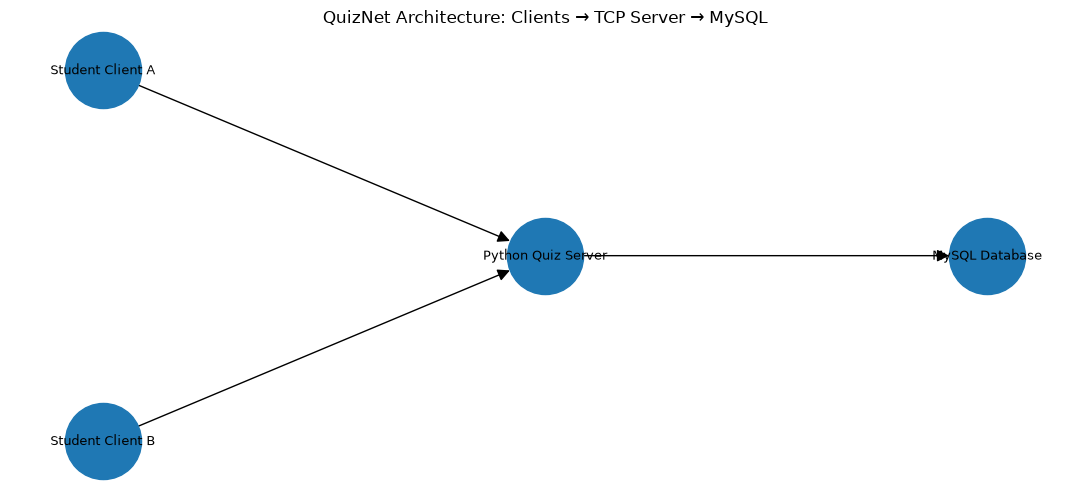

Path from Student Client A to database: Student Client A -> Python Quiz Server -> MySQL Database
Path from Student Client B to database: Student Client B -> Python Quiz Server -> MySQL Database
Architecture nodes: 4
Architecture connections: 3


In [16]:
# Import the graph library and plotting library for the architecture visualization.
import networkx as nx
import matplotlib.pyplot as plt

# Model the logical flow of the application as a directed graph.
architecture = nx.DiGraph()
architecture.add_edges_from([
    ("Student Client A", "Python Quiz Server"),
    ("Student Client B", "Python Quiz Server"),
    ("Python Quiz Server", "MySQL Database"),
])

# Display the graph. These positions are chosen only to make the diagram easy to read.
positions = {
    "Student Client A": (-1, 1),
    "Student Client B": (-1, -1),
    "Python Quiz Server": (0.8, 0),
    "MySQL Database": (2.6, 0),
}
plt.figure(figsize=(11, 5))
nx.draw_networkx(
    architecture,
    pos=positions,
    with_labels=True,
    node_size=3000,
    font_size=9,
    arrows=True,
    arrowsize=18,
)
plt.title("QuizNet Architecture: Clients → TCP Server → MySQL")
plt.axis("off")
plt.tight_layout()
plt.show()

# NetworkX analysis: confirm that each client has a logical path to the database.
for client in ["Student Client A", "Student Client B"]:
    path = nx.shortest_path(architecture, source=client, target="MySQL Database")
    print(f"Path from {client} to database: {' -> '.join(path)}")

print("Architecture nodes:", architecture.number_of_nodes())
print("Architecture connections:", architecture.number_of_edges())

## 17. Student performance graph -- using matplot

This graph reads the quiz attempts saved in MySQL and compares each student's percentage score. Run it after at least one player has completed a quiz. If the results table is empty, complete a quiz first.

C:\Users\Chandrashekara\AppData\Local\Temp\ipykernel_20324\2228844988.py:6: UserWarning: pandas only supports SQLAlchemy connectable (engine/connection) or database string URI or sqlite3 DBAPI2 connection. Other DBAPI2 objects are not tested. Please consider using SQLAlchemy.
  return pd.read_sql(


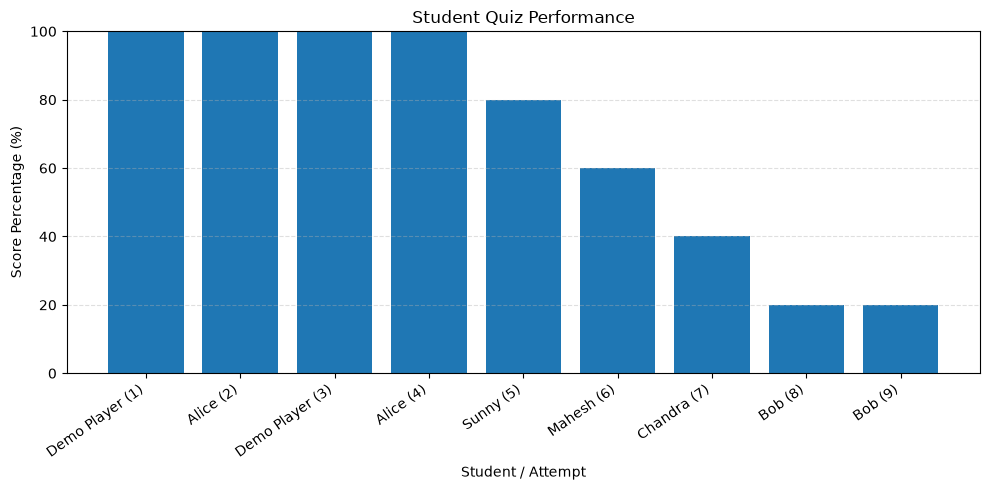

Performance data:


,player_name,score,total_questions,percentage
0,Demo Player,5,5,100.0
1,Alice,5,5,100.0
2,Demo Player,5,5,100.0
3,Alice,5,5,100.0
4,Sunny,4,5,80.0
5,Mahesh,3,5,60.0
6,Chandra,2,5,40.0
7,Bob,1,5,20.0
8,Bob,1,5,20.0


In [17]:
# Read saved attempts and draw a simple student performance chart.

performance = results_dataframe()

if performance.empty:
    print("No quiz results available yet. Complete a quiz first, then run this cell again.")
else:
    # Use player names on the x-axis and percentage scores on the y-axis.
    labels = [
        f"{row.player_name} ({i + 1})"
        for i, row in enumerate(performance.itertuples(index=False))
    ]

    plt.figure(figsize=(10, 5))
    plt.bar(labels, performance["percentage"])
    plt.title("Student Quiz Performance")
    plt.xlabel("Student / Attempt")
    plt.ylabel("Score Percentage (%)")
    plt.ylim(0, 100)
    plt.xticks(rotation=35, ha="right")
    plt.grid(axis="y", linestyle="--", alpha=0.4)
    plt.tight_layout()
    plt.show()

    print("Performance data:")
    display(performance[["player_name", "score", "total_questions", "percentage"]])
